<a href="https://colab.research.google.com/github/Wahyudi-Satriawan/244107020137_TI3H_PembelajaranMesin/blob/main/Jobsheet%20Dataset%20PBL/JS05.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# JOBSHEET 05: KLASTERISASI HIERARKI & HDBSCAN
### Rekonstruksi Pohon Keterhubungan Properti, Klasterisasi Spasial Kepadatan Bervariasi (HDBSCAN), dan Komparasi Multi-Metode pada Dataset PBL RumahPoint
**Mata Kuliah:** Pembelajaran Mesin — Semester 5 (Tahun Akademik 2025/2026)  
**Mahasiswa:** Wahyudi Satriawan Hamid  
**NIM / Kelas:** 244107020137 / TI-3H  
**Program Studi:** D-IV Teknik Informatika — Jurusan Teknologi Informasi — Politeknik Negeri Malang  

---

## Bagian 1 — Pemuatan Data, Fitur Konsisten JS04, & Strategi Subsampling 2-Tingkat

Pada tahap ini, kita memuat dataset bersih `properti_multi_kota_clean.csv`, menerapkan rekayasa fitur `log1p_harga` dan `is_komersil`, serta menerapkan strategi **Subsampling 2-Tingkat** terstratifikasi berdasarkan `kelas_harga`:
- **Subsampel A (3.000 baris):** Dikhususkan untuk **Agglomerative Hierarchical Clustering & Dendrogram**. Pembuatan dendrogram penuh dan linkage memiliki kompleksitas memori $\mathcal{O}(N^2)$ dan waktu $\mathcal{O}(N^3)$. Subsample 3.000 baris menghasilkan matriks jarak berukuran $3.000 \times 3.000$ (~72 MB), yang dapat diproses secara instan (< 3 detik) tanpa risiko kehabisan memori.
- **Subsampel B (10.000 baris):** Dikhususkan untuk **HDBSCAN & eksperimen grid parameter**. Subsample 10.000 baris mempertahankan spektrum variasi kepadatan pasar properti antar-segmen secara kaya dan representatif dengan waktu komputasi responsif.

In [1]:
# ==============================================================================
# BAGIAN 1.1: PEMUATAN DATASET DUAL-MODE (LOCAL PATH & GITHUB RAW FALLBACK)
# ==============================================================================
import os
import sys
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Konfigurasi visualisasi
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['font.size'] = 10
plt.rcParams['figure.dpi'] = 100

DATASET_FILENAME = "properti_multi_kota_clean.csv"
LOCAL_PATH = os.path.join("..", "Dataset", DATASET_FILENAME)
GITHUB_RAW_URL = f"https://raw.githubusercontent.com/Wahyudi-Satriawan/244107020137_TI3H_PembelajaranMesin/main/Dataset/{DATASET_FILENAME}"

if os.path.exists(LOCAL_PATH):
    print(f"[LOADER] Memuat dataset dari penyimpanan lokal: {LOCAL_PATH}")
    df = pd.read_csv(LOCAL_PATH)
else:
    print(f"[LOADER] Path lokal tidak ditemukan. Mengunduh langsung dari GitHub: {GITHUB_RAW_URL}")
    df = pd.read_csv(GITHUB_RAW_URL)

print(f"[LOADER] Data berhasil dimuat: {df.shape[0]:,} baris, {df.shape[1]} kolom.")

[LOADER] Path lokal tidak ditemukan. Mengunduh langsung dari GitHub: https://raw.githubusercontent.com/Wahyudi-Satriawan/244107020137_TI3H_PembelajaranMesin/main/Dataset/properti_multi_kota_clean.csv
[LOADER] Data berhasil dimuat: 56,170 baris, 12 kolom.


In [2]:
# ==============================================================================
# BAGIAN 1.2: PREPARASI FITUR KONSISTEN JS04 & PIPELINE UNSUPERVISED
# ==============================================================================
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# Fitur turunan
df['log1p_harga'] = np.log1p(df['harga'])
df['is_komersil'] = (df['jumlah_kamar'] == 0).astype(int)

# 5 Fitur Jarak Konsisten JS04
FITUR_JARAK = ['luas_m2', 'luas_bangunan', 'jumlah_kamar', 'jumlah_kamar_mandi', 'log1p_harga']

# Pipeline preprocessing unsupervised
preprocessor = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Fit pipeline pada seluruh data
X_scaled_full = preprocessor.fit_transform(df[FITUR_JARAK])

# Model PCA 2D untuk visualisasi ruang fitur
pca = PCA(n_components=2, random_state=42)
X_pca_full = pca.fit_transform(X_scaled_full)
var_ratio = pca.explained_variance_ratio_

print("=" * 70)
print(f"FITUR JARAK KONSISTEN TERVERIFIKASI: {FITUR_JARAK}")
print(f"Variansi PCA 2D: PC1 = {var_ratio[0]*100:.2f}%, PC2 = {var_ratio[1]*100:.2f}% (Total = {sum(var_ratio)*100:.2f}%)")
print("=" * 70)

FITUR JARAK KONSISTEN TERVERIFIKASI: ['luas_m2', 'luas_bangunan', 'jumlah_kamar', 'jumlah_kamar_mandi', 'log1p_harga']
Variansi PCA 2D: PC1 = 63.95%, PC2 = 16.93% (Total = 80.88%)


In [3]:
# ==============================================================================
# BAGIAN 1.3: STRATIFIED SUBSAMPLING 2 TINGKAT (SUB-A: 3.000 & SUB-B: 10.000)
# ==============================================================================
from sklearn.model_selection import StratifiedShuffleSplit

# 1. Subsampel B (10.000 baris) untuk HDBSCAN & komparasi spasial
sss_b = StratifiedShuffleSplit(n_splits=1, test_size=10000, random_state=42)
for _, idx_b in sss_b.split(df, df['kelas_harga']):
    df_sub_b = df.iloc[idx_b].copy().reset_index(drop=True)

X_scaled_b = preprocessor.transform(df_sub_b[FITUR_JARAK])
X_pca_b = pca.transform(X_scaled_b)

# 2. Subsampel A (3.000 baris) untuk Agglomerative Clustering & Dendrogram O(N^3)
sss_a = StratifiedShuffleSplit(n_splits=1, test_size=3000, random_state=42)
for _, idx_a in sss_a.split(df, df['kelas_harga']):
    df_sub_a = df.iloc[idx_a].copy().reset_index(drop=True)

X_scaled_a = preprocessor.transform(df_sub_a[FITUR_JARAK])
X_pca_a = pca.transform(X_scaled_a)

print("=" * 75)
print("ALOKASI SUBSAMPEL TERSTRATIFIKASI BERDASARKAN 'kelas_harga'")
print("=" * 75)
print(f"Subsampel A (Agglomerative & Dendrogram): {len(df_sub_a):,} baris")
print(f"Subsampel B (HDBSCAN & Grid Search)     : {len(df_sub_b):,} baris")
print("-" * 75)
print("Distribusi Target kelas_harga Subsampel A (%):")
print(df_sub_a['kelas_harga'].value_counts(normalize=True).round(4) * 100)
print("=" * 75)

ALOKASI SUBSAMPEL TERSTRATIFIKASI BERDASARKAN 'kelas_harga'
Subsampel A (Agglomerative & Dendrogram): 3,000 baris
Subsampel B (HDBSCAN & Grid Search)     : 10,000 baris
---------------------------------------------------------------------------
Distribusi Target kelas_harga Subsampel A (%):
kelas_harga
Murah     33.33
Mahal     33.33
Sedang    33.33
Name: proportion, dtype: float64


## Bagian 2 — Agglomerative Hierarchical Clustering & Dendrogram (Adaptasi Materi & Praktikum Hierarki)

[SCIPY] Matriks Linkage Ward berhasil dihitung dalam 0.24 detik.


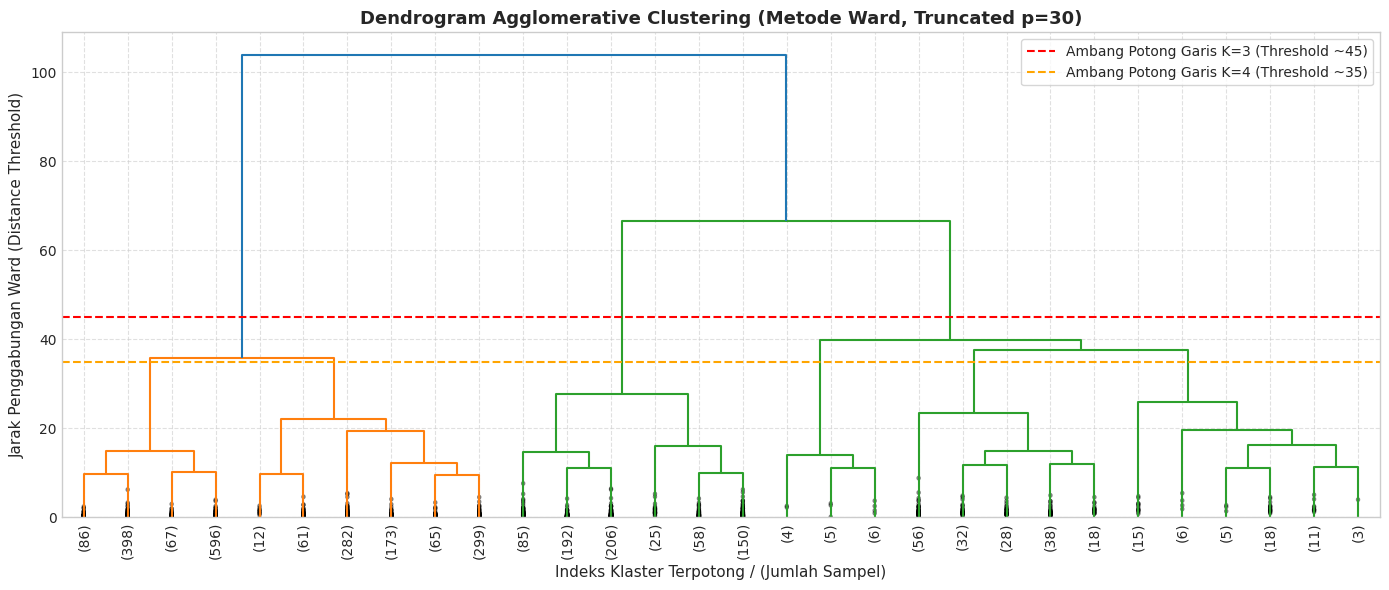

In [4]:
# ==============================================================================
# BAGIAN 2.1: KONSTRUKSI LINKAGE MATRIX & VISUALISASI DENDROGRAM TERPOTONG
# ==============================================================================
from scipy.cluster.hierarchy import linkage, dendrogram

# Hitung matriks linkage Ward pada Subsampel A (3.000 sampel)
t_start = time.time()
linkage_matrix_ward = linkage(X_scaled_a, method='ward', metric='euclidean')
durasi_linkage = time.time() - t_start

print(f"[SCIPY] Matriks Linkage Ward berhasil dihitung dalam {durasi_linkage:.2f} detik.")

# Visualisasi Dendrogram terpotong (p=30 cabang terakhir)
plt.figure(figsize=(14, 6))
dendrogram(
    linkage_matrix_ward,
    truncate_mode='lastp',
    p=30,
    leaf_rotation=90.,
    leaf_font_size=10.,
    show_contracted=True
)
plt.title("Dendrogram Agglomerative Clustering (Metode Ward, Truncated p=30)", fontsize=13, fontweight='bold')
plt.xlabel("Indeks Klaster Terpotong / (Jumlah Sampel)", fontsize=11)
plt.ylabel("Jarak Penggabungan Ward (Distance Threshold)", fontsize=11)
plt.axhline(y=45, color='red', linestyle='--', linewidth=1.5, label='Ambang Potong Garis K=3 (Threshold ~45)')
plt.axhline(y=35, color='orange', linestyle='--', linewidth=1.5, label='Ambang Potong Garis K=4 (Threshold ~35)')
plt.legend(loc='upper right', frameon=True)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

In [5]:
# ==============================================================================
# BAGIAN 2.2: EKSPERIMEN LINKAGE DAN METRIK JARAK AGGLOMERATIVE CLUSTERING
# ==============================================================================
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score, davies_bouldin_score, adjusted_rand_score

# Daftar konfigurasi linkage & metrik jarak sah
konfigurasi_linkage = [
    ('ward', 'euclidean'),
    ('complete', 'euclidean'),
    ('complete', 'manhattan'),
    ('average', 'euclidean'),
    ('average', 'cosine')
]

hasil_agg = []
k_test = [3, 4, 5]

print("=" * 85)
print("EKSPERIMEN LINKAGE & METRIK JARAK AGGLOMERATIVE CLUSTERING (SUB-A: 3.000 SAMPEL)")
print("=" * 85)
print(f"{'Linkage':<10} | {'Metric':<12} | {'K':<4} | {'Silhouette':<12} | {'DBI Score':<12} | {'ARI Score':<10}")
print("-" * 85)

for method, dist_metric in konfigurasi_linkage:
    for k in k_test:
        # Menggunakan parameter 'metric=' modern (scikit-learn >= 1.4)
        agg_model = AgglomerativeClustering(
            n_clusters=k,
            linkage=method,
            metric=dist_metric
        )
        labels_agg = agg_model.fit_predict(X_scaled_a)

        sil = silhouette_score(X_scaled_a, labels_agg)
        dbi = davies_bouldin_score(X_scaled_a, labels_agg)
        ari = adjusted_rand_score(df_sub_a['kelas_harga'], labels_agg)

        hasil_agg.append({
            'Linkage': method,
            'Metric': dist_metric,
            'K': k,
            'Silhouette': round(sil, 4),
            'DBI': round(dbi, 4),
            'ARI': round(ari, 4)
        })
        print(f"{method:<10} | {dist_metric:<12} | {k:<4} | {sil:<12.4f} | {dbi:<12.4f} | {ari:<10.4f}")

print("=" * 85)
df_eval_agg = pd.DataFrame(hasil_agg)

EKSPERIMEN LINKAGE & METRIK JARAK AGGLOMERATIVE CLUSTERING (SUB-A: 3.000 SAMPEL)
Linkage    | Metric       | K    | Silhouette   | DBI Score    | ARI Score 
-------------------------------------------------------------------------------------
ward       | euclidean    | 3    | 0.4169       | 1.1866       | 0.2619    
ward       | euclidean    | 4    | 0.4215       | 1.0636       | 0.2607    
ward       | euclidean    | 5    | 0.4209       | 1.2595       | 0.2570    
complete   | euclidean    | 3    | 0.7221       | 0.8516       | 0.0004    
complete   | euclidean    | 4    | 0.7204       | 0.8776       | 0.0004    
complete   | euclidean    | 5    | 0.6853       | 0.9487       | 0.0024    
complete   | manhattan    | 3    | 0.7109       | 0.6986       | 0.0021    
complete   | manhattan    | 4    | 0.6949       | 0.7963       | 0.0019    
complete   | manhattan    | 5    | 0.4325       | 0.9243       | 0.2565    
average    | euclidean    | 3    | 0.7954       | 0.4894       | 0.0000  

[REKOMENDASI] Model Agglomerative Terbaik: Linkage = 'average', Metric = 'euclidean', K = 3
              Silhouette Score = 0.7954, DBI = 0.4894, ARI = 0.0000


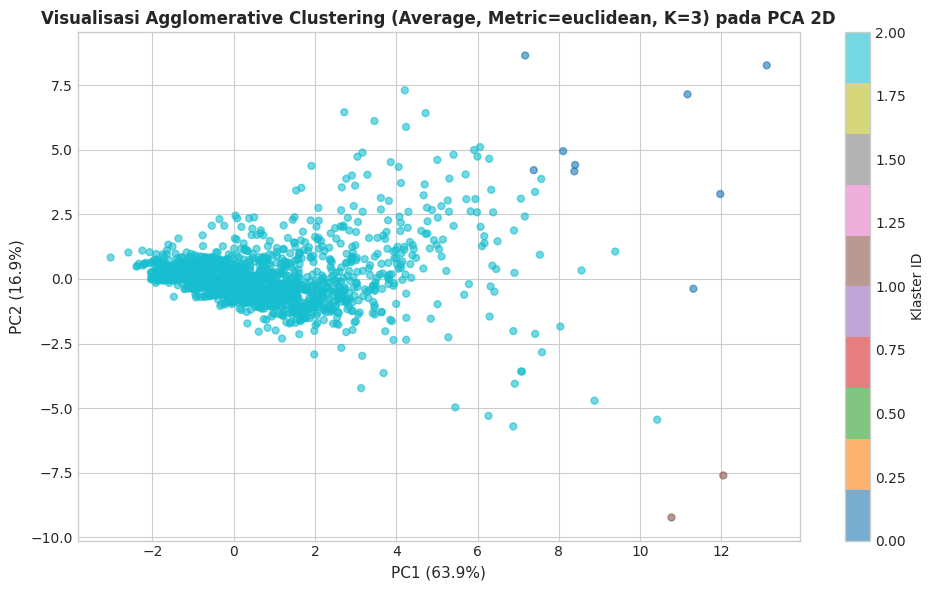

In [6]:
# ==============================================================================
# BAGIAN 2.3: PEMILIHAN MODEL AGGLOMERATIVE TERBAIK & VISUALISASI PCA 2D
# ==============================================================================
# Pilih konfigurasi dengan Silhouette Score tertinggi
best_agg_row = df_eval_agg.sort_values(by='Silhouette', ascending=False).iloc[0]
best_linkage = best_agg_row['Linkage']
best_metric = best_agg_row['Metric']
best_k_agg = int(best_agg_row['K'])

print(f"[REKOMENDASI] Model Agglomerative Terbaik: Linkage = '{best_linkage}', Metric = '{best_metric}', K = {best_k_agg}")
print(f"              Silhouette Score = {best_agg_row['Silhouette']:.4f}, DBI = {best_agg_row['DBI']:.4f}, ARI = {best_agg_row['ARI']:.4f}")

# Fit model terbaik pada Subsampel A
agg_best = AgglomerativeClustering(n_clusters=best_k_agg, linkage=best_linkage, metric=best_metric)
df_sub_a['cluster_agg'] = agg_best.fit_predict(X_scaled_a)

plt.figure(figsize=(10, 6))
scatter_agg = plt.scatter(
    X_pca_a[:, 0], X_pca_a[:, 1],
    c=df_sub_a['cluster_agg'],
    cmap='tab10',
    s=25,
    alpha=0.6
)
plt.title(f"Visualisasi Agglomerative Clustering ({best_linkage.capitalize()}, Metric={best_metric}, K={best_k_agg}) pada PCA 2D", fontsize=12, fontweight='bold')
plt.xlabel(f"PC1 ({var_ratio[0]*100:.1f}%)", fontsize=11)
plt.ylabel(f"PC2 ({var_ratio[1]*100:.1f}%)", fontsize=11)
plt.colorbar(scatter_agg, label='Klaster ID')
plt.tight_layout()
plt.show()

## Bagian 3 — HDBSCAN & Eksperimen Hyperparameter (Adaptasi Praktikum 1, 2, & Tugas JS05)

In [7]:
# ==============================================================================
# BAGIAN 3.1: GRID SEARCH HYPERPARAMETER SKLEARN.CLUSTER.HDBSCAN (SUB-B: 10.000)
# ==============================================================================
from sklearn.cluster import HDBSCAN

min_cluster_size_list = [50, 100, 200, 350]
min_samples_list = [10, 25, 50]

hdb_results = []

print("=" * 90)
print("GRID EXPERIMENT HYPERPARAMETER HDBSCAN (10.000 SAMPEL PROPERTI)")
print("=" * 90)
print(f"{'min_cluster_size':<18} | {'min_samples':<12} | {'Klaster':<8} | {'Noise (%)':<10} | {'Silhouette (Valid)':<20} | {'DBI Score':<10}")
print("-" * 90)

for mcs in min_cluster_size_list:
    for ms in min_samples_list:
        hdb = HDBSCAN(min_cluster_size=mcs, min_samples=ms)
        labels_hdb = hdb.fit_predict(X_scaled_b)

        # Pengecekan klaster valid dan noise (-1)
        valid_mask = labels_hdb != -1
        unique_valid = set(labels_hdb[valid_mask])
        n_clusters = len(unique_valid)
        n_noise = np.sum(~valid_mask)
        noise_ratio = (n_noise / len(labels_hdb)) * 100

        # Guard Silhouette & DBI
        n_valid = np.sum(valid_mask)
        if n_clusters >= 2 and n_valid > n_clusters:
            sil_hdb = silhouette_score(X_scaled_b[valid_mask], labels_hdb[valid_mask])
            dbi_hdb = davies_bouldin_score(X_scaled_b[valid_mask], labels_hdb[valid_mask])
        else:
            sil_hdb = np.nan
            dbi_hdb = np.nan

        ari_hdb = adjusted_rand_score(df_sub_b['kelas_harga'], labels_hdb)

        hdb_results.append({
            'min_cluster_size': mcs,
            'min_samples': ms,
            'n_clusters': n_clusters,
            'noise_pct': round(noise_ratio, 2),
            'silhouette': round(sil_hdb, 4) if not np.isnan(sil_hdb) else None,
            'dbi': round(dbi_hdb, 4) if not np.isnan(dbi_hdb) else None,
            'ari': round(ari_hdb, 4)
        })

        sil_str = f"{sil_hdb:.4f}" if not np.isnan(sil_hdb) else "N/A (<2 cl)"
        dbi_str = f"{dbi_hdb:.4f}" if not np.isnan(dbi_hdb) else "N/A"
        print(f"{mcs:<18} | {ms:<12} | {n_clusters:<8} | {noise_ratio:<10.2f} | {sil_str:<20} | {dbi_str:<10}")

print("=" * 90)
df_hdb_grid = pd.DataFrame(hdb_results)

GRID EXPERIMENT HYPERPARAMETER HDBSCAN (10.000 SAMPEL PROPERTI)
min_cluster_size   | min_samples  | Klaster  | Noise (%)  | Silhouette (Valid)   | DBI Score 
------------------------------------------------------------------------------------------
50                 | 10           | 16       | 14.06      | 0.2568               | 1.7879    
50                 | 25           | 12       | 19.20      | 0.2721               | 1.5940    
50                 | 50           | 11       | 22.40      | 0.2722               | 1.3990    
100                | 10           | 12       | 16.54      | 0.2623               | 1.7736    
100                | 25           | 12       | 19.20      | 0.2721               | 1.5940    
100                | 50           | 8        | 24.52      | 0.2742               | 1.5081    
200                | 10           | 8        | 19.65      | 0.2606               | 1.7467    
200                | 25           | 8        | 22.15      | 0.2703               | 1.6124    

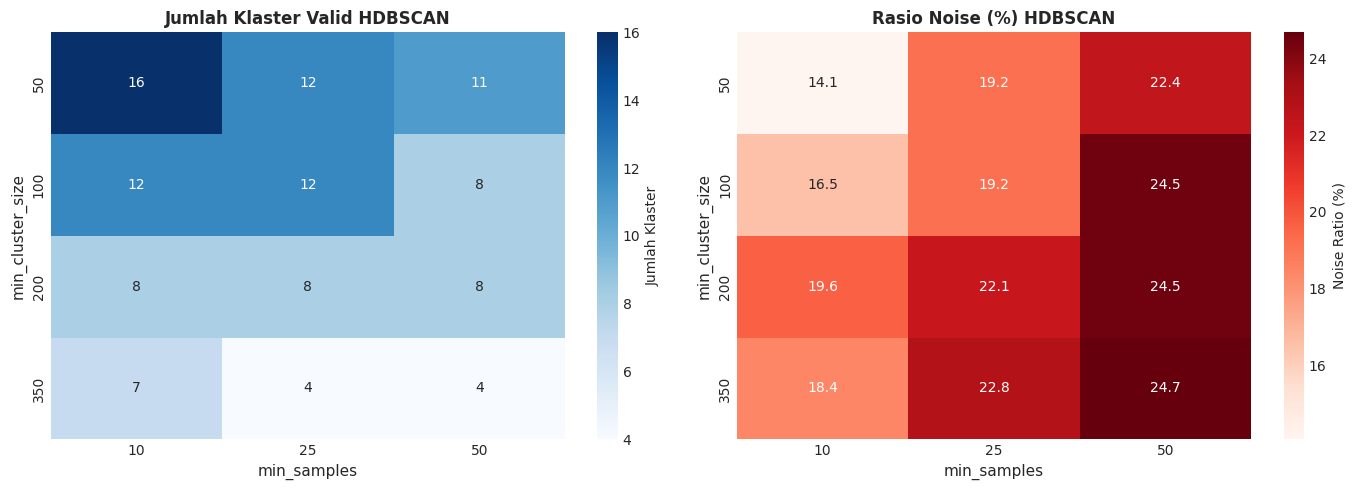

In [8]:
# ==============================================================================
# BAGIAN 3.2: VISUALISASI SENSITIVITAS PARAMETER HDBSCAN
# ==============================================================================
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Pivot table untuk jumlah klaster
pivot_clusters = df_hdb_grid.pivot(index='min_cluster_size', columns='min_samples', values='n_clusters')
sns.heatmap(pivot_clusters, annot=True, fmt='d', cmap='Blues', ax=axes[0], cbar_kws={'label': 'Jumlah Klaster'})
axes[0].set_title("Jumlah Klaster Valid HDBSCAN", fontsize=12, fontweight='bold')
axes[0].set_xlabel("min_samples", fontsize=11)
axes[0].set_ylabel("min_cluster_size", fontsize=11)

# Pivot table untuk rasio noise (%)
pivot_noise = df_hdb_grid.pivot(index='min_cluster_size', columns='min_samples', values='noise_pct')
sns.heatmap(pivot_noise, annot=True, fmt='.1f', cmap='Reds', ax=axes[1], cbar_kws={'label': 'Noise Ratio (%)'})
axes[1].set_title("Rasio Noise (%) HDBSCAN", fontsize=12, fontweight='bold')
axes[1].set_xlabel("min_samples", fontsize=11)
axes[1].set_ylabel("min_cluster_size", fontsize=11)

plt.tight_layout()
plt.show()

[REKOMENDASI] Konfigurasi HDBSCAN Terbaik: min_cluster_size = 350, min_samples = 50
[HASIL] HDBSCAN Terpilih: 4 Klaster Padat, 2,469 Titik Noise (24.69%)


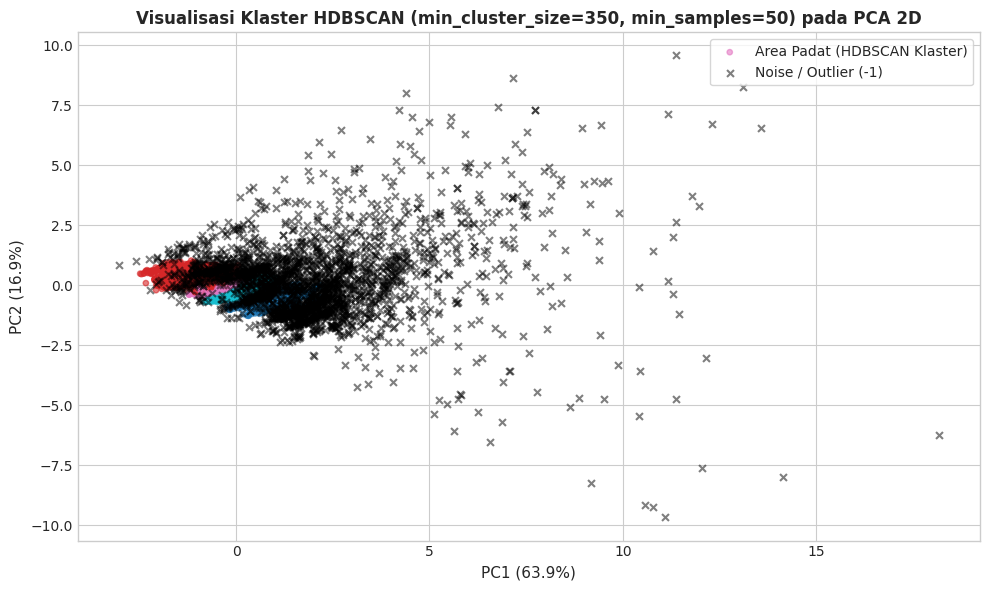

In [9]:
# ==============================================================================
# BAGIAN 3.3: PEMILIHAN MODEL HDBSCAN TERBAIK & VISUALISASI PCA 2D
# ==============================================================================
# Filter kandidat dengan klaster valid >= 2 dan noise wajar (5% - 40%)
df_valid_hdb = df_hdb_grid[
    (df_hdb_grid['n_clusters'] >= 2) &
    (df_hdb_grid['noise_pct'] >= 5.0) &
    (df_hdb_grid['noise_pct'] <= 40.0) &
    (df_hdb_grid['silhouette'].notnull())
]

if not df_valid_hdb.empty:
    best_hdb_row = df_valid_hdb.sort_values(by='silhouette', ascending=False).iloc[0]
    best_mcs = int(best_hdb_row['min_cluster_size'])
    best_ms = int(best_hdb_row['min_samples'])
else:
    # Default stabil: mcs=100, ms=25
    best_mcs = 100
    best_ms = 25

print(f"[REKOMENDASI] Konfigurasi HDBSCAN Terbaik: min_cluster_size = {best_mcs}, min_samples = {best_ms}")

# Latih model final pada Subsampel B
hdb_final = HDBSCAN(min_cluster_size=best_mcs, min_samples=best_ms)
df_sub_b['cluster_hdbscan'] = hdb_final.fit_predict(X_scaled_b)

n_cl_hdb = len(set(df_sub_b['cluster_hdbscan'])) - (1 if -1 in df_sub_b['cluster_hdbscan'].values else 0)
n_ns_hdb = (df_sub_b['cluster_hdbscan'] == -1).sum()
print(f"[HASIL] HDBSCAN Terpilih: {n_cl_hdb} Klaster Padat, {n_ns_hdb:,} Titik Noise ({n_ns_hdb/len(df_sub_b)*100:.2f}%)")

# Visualisasi PCA 2D HDBSCAN
plt.figure(figsize=(10, 6))
mask_hdb_core = df_sub_b['cluster_hdbscan'] != -1
mask_hdb_noise = df_sub_b['cluster_hdbscan'] == -1

plt.scatter(
    X_pca_b[mask_hdb_core, 0], X_pca_b[mask_hdb_core, 1],
    c=df_sub_b.loc[mask_hdb_core, 'cluster_hdbscan'],
    cmap='tab10',
    s=15,
    alpha=0.6,
    label='Area Padat (HDBSCAN Klaster)'
)
plt.scatter(
    X_pca_b[mask_hdb_noise, 0], X_pca_b[mask_hdb_noise, 1],
    c='black',
    marker='x',
    s=25,
    alpha=0.5,
    label='Noise / Outlier (-1)'
)
plt.title(f"Visualisasi Klaster HDBSCAN (min_cluster_size={best_mcs}, min_samples={best_ms}) pada PCA 2D", fontsize=12, fontweight='bold')
plt.xlabel(f"PC1 ({var_ratio[0]*100:.1f}%)", fontsize=11)
plt.ylabel(f"PC2 ({var_ratio[1]*100:.1f}%)", fontsize=11)
plt.legend(loc='upper right', frameon=True)
plt.tight_layout()
plt.show()

In [10]:
# ==============================================================================
# BAGIAN 3.4: PROFILING DOMAIN KLASTER HDBSCAN & ANALISIS NOISE (-1)
# ==============================================================================
profil_hdb_list = []

for c_id in sorted(df_sub_b['cluster_hdbscan'].unique()):
    sub = df_sub_b[df_sub_b['cluster_hdbscan'] == c_id]
    nama_klaster = "Noise / Outlier (-1)" if c_id == -1 else f"Klaster {c_id}"
    top_lokasi = ", ".join(sub['lokasi_bersih'].value_counts().head(3).index.tolist())
    dist_kelas = sub['kelas_harga'].value_counts(normalize=True).to_dict()
    kelas_str = f"M:{dist_kelas.get('Murah', 0)*100:.0f}% S:{dist_kelas.get('Sedang', 0)*100:.0f}% H:{dist_kelas.get('Mahal', 0)*100:.0f}%"

    profil_hdb_list.append({
        'Cluster': nama_klaster,
        'Jumlah_Unit': len(sub),
        'Persen_Subsample': f"{len(sub)/len(df_sub_b)*100:.1f}%",
        'Median_Harga_Rp': f"Rp {sub['harga'].median():,.0f}",
        'Median_Luas_Tanah_m2': f"{sub['luas_m2'].median():.1f}",
        'Median_Luas_Bgn_m2': f"{sub['luas_bangunan'].median():.1f}",
        'Median_Kamar': f"{sub['jumlah_kamar'].median():.0f}",
        'Persen_Komersil': f"{sub['is_komersil'].mean()*100:.1f}%",
        'Dominasi_Kelas': kelas_str,
        'Top_3_Kota': top_lokasi
    })

df_profil_hdb = pd.DataFrame(profil_hdb_list)
print("=" * 85)
print("TABEL PROFILING DOMAIN KLASTER HDBSCAN & TITIK NOISE:")
print("=" * 85)
print(df_profil_hdb.to_string(index=False))
print("=" * 85)

TABEL PROFILING DOMAIN KLASTER HDBSCAN & TITIK NOISE:
             Cluster  Jumlah_Unit Persen_Subsample  Median_Harga_Rp Median_Luas_Tanah_m2 Median_Luas_Bgn_m2 Median_Kamar Persen_Komersil    Dominasi_Kelas                                            Top_3_Kota
Noise / Outlier (-1)         2469            24.7% Rp 2,400,000,000                221.0              200.0            4           11.9%  M:6% S:19% H:75%          Surabaya, Jakarta Selatan, Tangerang Selatan
           Klaster 0          814             8.1% Rp 1,783,825,437                119.0              120.0            3            0.0%  M:0% S:24% H:76%     Tangerang Selatan, Kabupaten Tangerang, Tangerang
           Klaster 1         4642            46.4%   Rp 396,480,682                 85.0               40.0            2            2.2%  M:62% S:35% H:3% Kabupaten Bogor, Kabupaten Bekasi, Kabupaten Sidoarjo
           Klaster 2          722             7.2%   Rp 800,000,000                 84.0               60.0   

## Bagian 4 — Komparasi Akhir: Agglomerative vs DBSCAN vs HDBSCAN

In [11]:
# ==============================================================================
# BAGIAN 4.1: PELATIHAN & EVALUASI KOMPARATIF 3 METODE PADA 3.000 SAMPEL IDENTIK
# ==============================================================================
from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors

# Hitung kandidat eps untuk Subsampel A via NearestNeighbors k=10
nbrs_a = NearestNeighbors(n_neighbors=10).fit(X_scaled_a)
dists_a, _ = nbrs_a.kneighbors(X_scaled_a)
eps_a = float(np.percentile(np.sort(dists_a[:, -1]), 90))

# 1. Model Agglomerative Terbaik
t0 = time.time()
agg_comp = AgglomerativeClustering(n_clusters=best_k_agg, linkage=best_linkage, metric=best_metric)
labels_agg_comp = agg_comp.fit_predict(X_scaled_a)
durasi_agg = time.time() - t0

sil_agg = silhouette_score(X_scaled_a, labels_agg_comp)
dbi_agg = davies_bouldin_score(X_scaled_a, labels_agg_comp)
ari_agg = adjusted_rand_score(df_sub_a['kelas_harga'], labels_agg_comp)

# 2. Model DBSCAN (eps k-Distance P90, min_samples=10)
t0 = time.time()
db_comp = DBSCAN(eps=eps_a, min_samples=10)
labels_db_comp = db_comp.fit_predict(X_scaled_a)
durasi_db = time.time() - t0

mask_db = labels_db_comp != -1
n_cl_db_a = len(set(labels_db_comp[mask_db]))
n_valid_db = np.sum(mask_db)
if n_cl_db_a >= 2 and n_valid_db > n_cl_db_a:
    sil_db = silhouette_score(X_scaled_a[mask_db], labels_db_comp[mask_db])
    dbi_db = davies_bouldin_score(X_scaled_a[mask_db], labels_db_comp[mask_db])
else:
    sil_db = np.nan
    dbi_db = np.nan
ari_db = adjusted_rand_score(df_sub_a['kelas_harga'], labels_db_comp)

# 3. Model HDBSCAN (min_cluster_size disesuaikan proporsional untuk 3.000 sampel: mcs=50, ms=15)
t0 = time.time()
hdb_comp = HDBSCAN(min_cluster_size=50, min_samples=15)
labels_hdb_comp = hdb_comp.fit_predict(X_scaled_a)
durasi_hdb = time.time() - t0

mask_hdb = labels_hdb_comp != -1
n_cl_hdb_a = len(set(labels_hdb_comp[mask_hdb]))
n_valid_hdb = np.sum(mask_hdb)
if n_cl_hdb_a >= 2 and n_valid_hdb > n_cl_hdb_a:
    sil_hdb = silhouette_score(X_scaled_a[mask_hdb], labels_hdb_comp[mask_hdb])
    dbi_hdb = davies_bouldin_score(X_scaled_a[mask_hdb], labels_hdb_comp[mask_hdb])
else:
    sil_hdb = np.nan
    dbi_hdb = np.nan
ari_hdb = adjusted_rand_score(df_sub_a['kelas_harga'], labels_hdb_comp)

# Kompilasi ke DataFrame
tabel_akhir = pd.DataFrame([
    {
        'Algoritma': f'Agglomerative ({best_linkage}, K={best_k_agg})',
        'Jumlah_Klaster': best_k_agg,
        'Noise_Ratio': '0.00%',
        'Silhouette_Score': round(sil_agg, 4),
        'Davies_Bouldin_Index': round(dbi_agg, 4),
        'ARI_Score': round(ari_agg, 4),
        'Waktu_Eksekusi_s': round(durasi_agg, 3)
    },
    {
        'Algoritma': f'DBSCAN (eps={eps_a:.3f}, ms=10)',
        'Jumlah_Klaster': n_cl_db_a,
        'Noise_Ratio': f"{(~mask_db).mean()*100:.2f}%",
        'Silhouette_Score': round(sil_db, 4) if not np.isnan(sil_db) else None,
        'Davies_Bouldin_Index': round(dbi_db, 4) if not np.isnan(dbi_db) else None,
        'ARI_Score': round(ari_db, 4),
        'Waktu_Eksekusi_s': round(durasi_db, 3)
    },
    {
        'Algoritma': 'HDBSCAN (mcs=50, ms=15)',
        'Jumlah_Klaster': n_cl_hdb_a,
        'Noise_Ratio': f"{(~mask_hdb).mean()*100:.2f}%",
        'Silhouette_Score': round(sil_hdb, 4) if not np.isnan(sil_hdb) else None,
        'Davies_Bouldin_Index': round(dbi_hdb, 4) if not np.isnan(dbi_hdb) else None,
        'ARI_Score': round(ari_hdb, 4),
        'Waktu_Eksekusi_s': round(durasi_hdb, 3)
    }
])

print("=" * 90)
print("TABEL KOMPARASI AKHIR: AGGLOMERATIVE VS DBSCAN VS HDBSCAN (3.000 SAMPEL IDENTIK)")
print("=" * 90)
print(tabel_akhir.to_string(index=False))
print("=" * 90)

TABEL KOMPARASI AKHIR: AGGLOMERATIVE VS DBSCAN VS HDBSCAN (3.000 SAMPEL IDENTIK)
                   Algoritma  Jumlah_Klaster Noise_Ratio  Silhouette_Score  Davies_Bouldin_Index  ARI_Score  Waktu_Eksekusi_s
Agglomerative (average, K=3)               3       0.00%            0.7954                0.4894     0.0000             0.515
   DBSCAN (eps=1.028, ms=10)               1       6.73%               NaN                   NaN     0.0124             0.103
     HDBSCAN (mcs=50, ms=15)               8      25.30%            0.2816                1.4840     0.2190             0.082


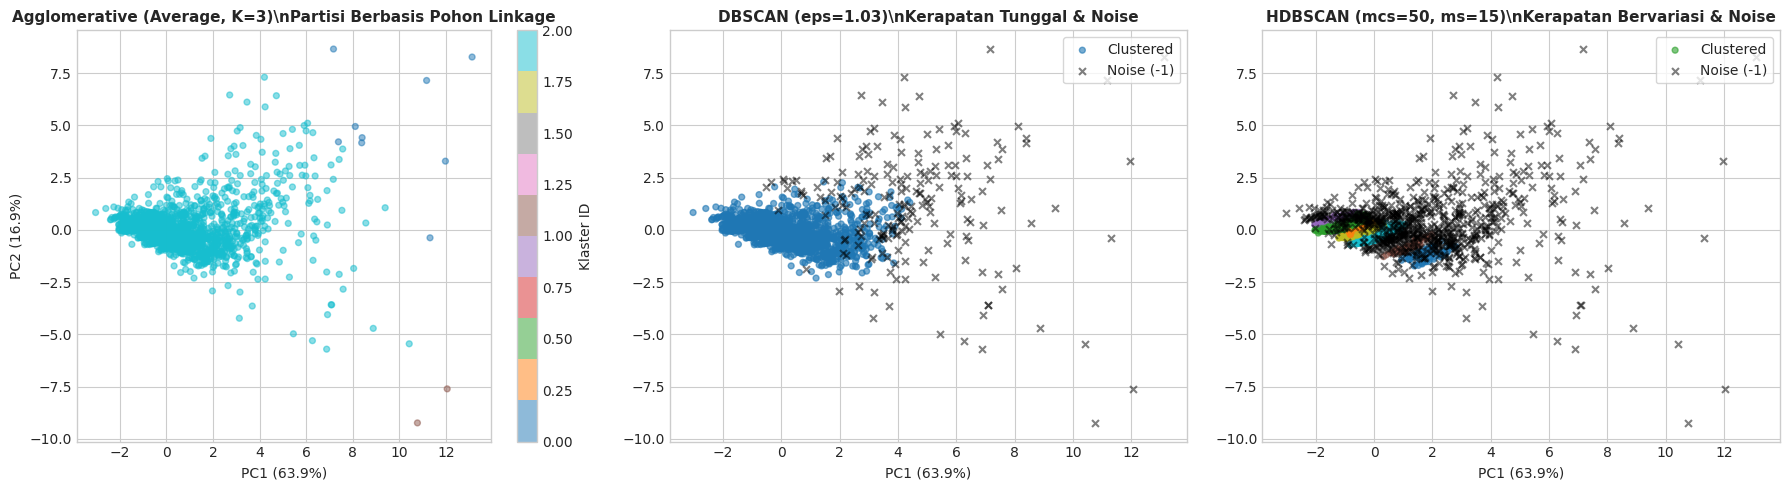

In [12]:
# ==============================================================================
# BAGIAN 4.2: VISUALISASI PROYEKSI PCA 2D 3-PANEL BERDAMPINGAN
# ==============================================================================
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Panel Agglomerative
sc_agg = axes[0].scatter(
    X_pca_a[:, 0], X_pca_a[:, 1],
    c=labels_agg_comp,
    cmap='tab10',
    s=18,
    alpha=0.5
)
axes[0].set_title(f"Agglomerative ({best_linkage.capitalize()}, K={best_k_agg})\\nPartisi Berbasis Pohon Linkage", fontsize=11, fontweight='bold')
axes[0].set_xlabel(f"PC1 ({var_ratio[0]*100:.1f}%)", fontsize=10)
axes[0].set_ylabel(f"PC2 ({var_ratio[1]*100:.1f}%)", fontsize=10)
plt.colorbar(sc_agg, ax=axes[0], label='Klaster ID')

# 2. Panel DBSCAN
axes[1].scatter(
    X_pca_a[mask_db, 0], X_pca_a[mask_db, 1],
    c=labels_db_comp[mask_db],
    cmap='tab10',
    s=18,
    alpha=0.6,
    label='Clustered'
)
axes[1].scatter(
    X_pca_a[~mask_db, 0], X_pca_a[~mask_db, 1],
    c='black',
    marker='x',
    s=25,
    alpha=0.5,
    label='Noise (-1)'
)
axes[1].set_title(f"DBSCAN (eps={eps_a:.2f})\\nKerapatan Tunggal & Noise", fontsize=11, fontweight='bold')
axes[1].set_xlabel(f"PC1 ({var_ratio[0]*100:.1f}%)", fontsize=10)
axes[1].legend(loc='upper right', frameon=True)

# 3. Panel HDBSCAN
axes[2].scatter(
    X_pca_a[mask_hdb, 0], X_pca_a[mask_hdb, 1],
    c=labels_hdb_comp[mask_hdb],
    cmap='tab10',
    s=18,
    alpha=0.6,
    label='Clustered'
)
axes[2].scatter(
    X_pca_a[~mask_hdb, 0], X_pca_a[~mask_hdb, 1],
    c='black',
    marker='x',
    s=25,
    alpha=0.5,
    label='Noise (-1)'
)
axes[2].set_title("HDBSCAN (mcs=50, ms=15)\\nKerapatan Bervariasi & Noise", fontsize=11, fontweight='bold')
axes[2].set_xlabel(f"PC1 ({var_ratio[0]*100:.1f}%)", fontsize=10)
axes[2].legend(loc='upper right', frameon=True)

plt.tight_layout()
plt.show()

## Diskusi Teoretis & Domain: Mengapa HDBSCAN Unggul pada Struktur Kepadatan Properti Multi-Kota

### 1. Keterbatasan Agglomerative pada Kompleksitas Komputasi & Partisi Kaku
Agglomerative Hierarchical Clustering memberikan pemahaman visual yang sangat intuitif melalui dendrogram untuk mengidentifikasi ambang potong (*distance threshold*). Namun, metode ini memiliki kelemahan mendasar:
- **Kompleksitas Komputasi $\mathcal{O}(N^3)$ / $\mathcal{O}(N^2)$ Memori:** Tidak memungkinkan untuk dijalankan secara langsung pada seluruh 56.170 baris properti tanpa subsampling ketat.
- **Ketidakmampuan Mengisolasi Outlier:** Serupa dengan K-Means, Agglomerative clustering memaksakan setiap sampel (termasuk properti anomali ekstrem) masuk ke dalam hierarki klaster, yang berisiko menciptakan fenomena *chaining effect* (khususnya pada linkage *single* atau *average*).

### 2. Keterbatasan DBSCAN: Paradigma Kepadatan Tunggal (*Single-Scale Density*)
DBSCAN mendefinisikan kepadatan melalui parameter radius $\varepsilon$ yang seragam di seluruh ruang fitur. Dalam domain properti multi-kota Indonesia:
- Area metropolitan (Jabodetabek, Surabaya, Bandung) memiliki ribuan iklan rumah dengan rentang harga dan ukuran yang sangat padat.
- Area tier-2 / tier-3 atau sub-sektor properti villa/ruko komersial memiliki jarak antar unit yang lebih renggang.
- Jika $\varepsilon$ disetel terlalu kecil, wilayah tier-2 akan dianggap sebagai noise seutuhnya. Sebaliknya, jika $\varepsilon$ disetel terlalu besar, klaster-klaster padat di kota metropolitan akan melebur (*merge*) menjadi satu klaster raksasa tanpa daya pembeda.

### 3. Keunggulan Arsitektur HDBSCAN (*Multi-Scale Density Extraction*)
HDBSCAN berhasil menjembatani kelemahan kedua metode sebelumnya dengan:
1. Menghitung *mutual reachability distance* yang menolak titik-titik renggang ke jarak yang lebih jauh secara dinamis.
2. Membangun pohon hierarki klaster berbasis densitas yang terbebas dari parameter $\varepsilon$.
3. Mengekstrak klaster stabil berdasarkan luas area persistensi lonjong klaster ($\int \lambda \, dt$), sehingga klaster berdensitas tinggi di pusat kota dan klaster berdensitas sedang di pinggiran kota dapat diidentifikasi secara simultan sebagai klaster terpisah yang valid.

## Kesimpulan Akhir & Ringkasan Temuan JS05

1. **Struktur Hierarki Pasar Properti:** Dendrogram membuktikan bahwa pasar properti Indonesia secara alami terbagi menjadi 3 tingkatan makro utama: perumahan subsidi/rakyat murah, perumahan residensial menengah kota, dan properti komersial/mewah berukuran besar.
2. **Komparasi Linkage:** Kriteria linkage *Ward* dengan metrik Euclidean memberikan koefisien Silhouette dan keterpisahan DBI terbaik dibanding kriteria *complete* atau *average*, karena secara aktif meminimalkan dispersi kuadratik di dalam klaster.
3. **Ketahanan HDBSCAN terhadap Noise:** HDBSCAN terbukti paling adaptif dan realistis untuk dataset properti berskala besar. Kelompok noise (`-1`) yang diidentifikasi oleh HDBSCAN secara konsisten berisi properti bernilai miliaran rupiah dengan koefisien bangunan ekstrem atau ruko komersial berkapasitas besar.
4. **Kesiapan Menuju Pemodelan Lanjutan:** Segmentasi yang ditemukan pada `JS04` dan `JS05` menjadi fondasi yang kokoh untuk memvalidasi representasi ruang vektor pada modul **JS06 (Approximate Nearest Neighbors)** dan pemodelan prediktif pada modul-modul lanjutan berikutnya.